## Lab 2 homework: Rijden de Treinen analytics

Before running this notebook I ran these commands in the terminal:
- in `lab02/`: `docker compose down -v` and `find data -type f -not -name '*.sql' -delete`, to remove the Postgres volume and the files from the lab, so the homework starts with fresh Postgres and DuckDB
- in `lab02-homework/`: `uv sync` and `docker compose up --detach`

### 1. Download data

In [1]:
BASE_URL = "https://opendata.rijdendetreinen.nl/public"

!wget -c -nv -P data {BASE_URL}/tariff-distances/tariff-distances-2022-01.csv
!wget -c -nv -P data {BASE_URL}/stations/stations-2023-09.csv

for year in range(2011, 2024):
    !wget -c -nv -P data {BASE_URL}/disruptions/disruptions-{year}.csv

for year in range(2019, 2026):
    !wget -c -nv -P data {BASE_URL}/services/services-{year}.csv.gz

### 2. Stations

In [2]:
import duckdb
import matplotlib.pyplot as plt

db = duckdb.connect("data/homework.duckdb")

In [3]:
db.sql("""
CREATE OR REPLACE TABLE stations AS
FROM 'data/stations-2023-09.csv'
""")

### 3. Distances

In [4]:
db.sql("""
CREATE OR REPLACE TABLE distances AS
FROM read_csv('data/tariff-distances-2022-01.csv', nullstr = 'XXX')
""")

db.sql("""
CREATE OR REPLACE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance
""")

### 4. Disruptions in Postgres

In [5]:
db.sql("INSTALL postgres; LOAD postgres;")

pg_conn_string = "host=localhost user=postgres password=postgres dbname=postgres"
db.sql(f"ATTACH IF NOT EXISTS '{pg_conn_string}' AS pg (TYPE postgres)")

db.sql("DROP TABLE IF EXISTS pg.disruptions")
db.sql("""
CREATE TABLE pg.disruptions AS
FROM 'data/disruptions-*.csv'
""")

### 5. Train services

In [6]:
db.sql("""
COPY (FROM 'data/services-*.csv.gz') TO 'data/services.parquet' (FORMAT parquet)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [7]:
db.sql("""
CREATE OR REPLACE TABLE services AS
FROM 'data/services.parquet'
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

### 7. Queries

7.1 How many trains departed from Amsterdam Central station overall?

In [8]:
db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS num_trains
FROM services
WHERE "Stop:Station code" = 'ASD'
  AND "Stop:Departure time" IS NOT NULL
""")

┌────────────┐
│ num_trains │
│   int64    │
├────────────┤
│    1940873 │
└────────────┘

7.2 Calculate the average arrival delay of different service types (`Service:Type`). Order results descending by average delay.

In [9]:
db.sql("""
SELECT
    "Service:Type",
    AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
GROUP BY ALL
ORDER BY avg_arrival_delay DESC
""").df()

,Service:Type,avg_arrival_delay
0,Alpen Express,31.842541
1,Krokus Express,18.304348
2,European Sleeper,14.262589
3,Nightjet,9.423911
4,ICE,7.766922
5,Eurostar,7.302105
6,ICE International,5.482791
7,Thalys,5.396190
8,Int. Trein,4.677561
9,Nachttrein,3.837050


7.3 What was the most common disruption cause in different years? MODE function may be useful.

In [10]:
db.sql("""
SELECT
    YEAR(start_time) AS year,
    MODE(statistical_cause_en) AS most_common_cause
FROM pg.disruptions
GROUP BY ALL
ORDER BY year
""")

┌───────┬───────────────────┐
│ year  │ most_common_cause │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
│  2023 │ broken down train │
├───────┴───────────────────┤
│ 13 rows         2 columns │
└───────────────────────────┘

7.4 How many trains started their overall service in any Amsterdam station?

In [11]:
db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS num_trains
FROM services
WHERE "Stop:Arrival time" IS NULL
  AND "Stop:Station code" IN (
      SELECT code
      FROM stations
      WHERE name_long LIKE 'Amsterdam%'
  )
""")

┌────────────┐
│ num_trains │
│   int64    │
├────────────┤
│    1272985 │
└────────────┘

7.5 What fraction of services was run to final destinations outside the Netherlands?

In [12]:
db.sql("""
SELECT
    COUNT(DISTINCT s."Service:RDT-ID") FILTER (WHERE st.country <> 'NL')
        / COUNT(DISTINCT s."Service:RDT-ID") AS fraction_outside_nl
FROM services AS s
LEFT JOIN stations AS st ON s."Stop:Station code" = st.code
WHERE s."Stop:Departure time" IS NULL
""")

┌──────────────────────┐
│ fraction_outside_nl  │
│        double        │
├──────────────────────┤
│ 0.037714929711991925 │
└──────────────────────┘

7.6 What is the largest distance between stations in the Netherlands (code NL)?

In [13]:
db.sql("""
SELECT
    s1.name_long AS station1,
    s2.name_long AS station2,
    distances_long.distance
FROM distances_long
JOIN stations s1 ON distances_long.station = s1.code
JOIN stations s2 ON distances_long.other_station = s2.code
WHERE s1.country = 'NL'
  AND s2.country = 'NL'
  AND station < other_station
ORDER BY distance DESC
LIMIT 1
""")

┌───────────┬────────────┬──────────┐
│ station1  │  station2  │ distance │
│  varchar  │  varchar   │  int64   │
├───────────┼────────────┼──────────┤
│ Eemshaven │ Vlissingen │      426 │
└───────────┴────────────┴──────────┘

7.7 Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them appropriately.

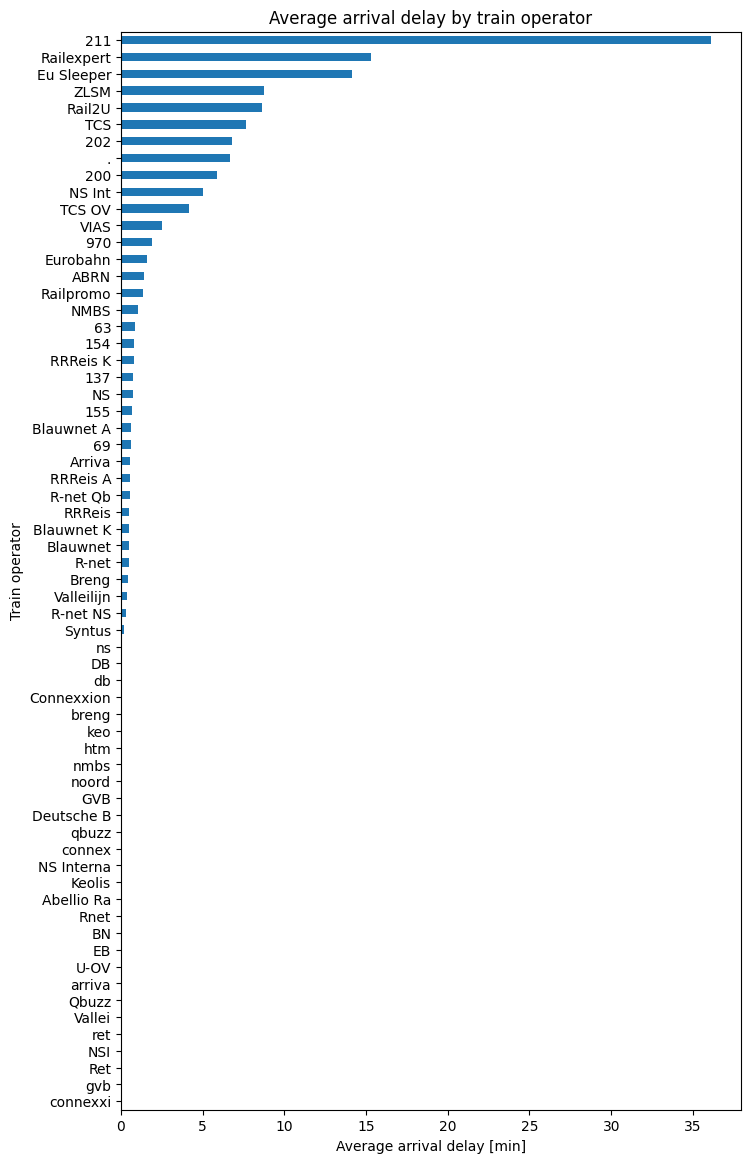

In [14]:
df_company_delays = db.sql("""
SELECT
    "Service:Company" AS company,
    AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
GROUP BY ALL
ORDER BY avg_arrival_delay
""").df()

ax = df_company_delays.plot.barh(x="company", y="avg_arrival_delay", legend=False, figsize=(8, 14))
ax.set_title("Average arrival delay by train operator")
ax.set_xlabel("Average arrival delay [min]")
ax.set_ylabel("Train operator")
plt.show()

7.8 How many services were disrupted in different years? Make a line plot.

I count a service as disrupted if it stopped at one of the stations from `rdt_station_codes` while the disruption was going on. The disruptions data ends in 2023 and the services data starts in 2019, so I can only answer this for 2019-2023.

The codes in `rdt_station_codes` are separated by a comma and a space (e.g. HNP, IJT, KMW), so I trim them after splitting. In the CSV files the service times have an offset (+01:00 / +02:00) and DuckDB converted them to UTC when reading, so in `services` they are in UTC. Disruption times have no offset, so I assumed they are in Dutch local time and converted them to UTC before comparing.

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

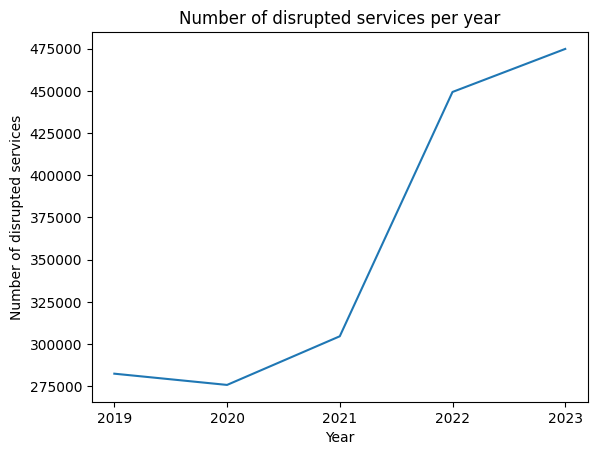

In [15]:
df_disrupted = db.sql("""
WITH disruption_stations AS (
    SELECT
        trim(unnest(string_split(rdt_station_codes, ','))) AS station_code,
        timezone('UTC', timezone('Europe/Amsterdam', start_time)) AS start_time,
        timezone('UTC', timezone('Europe/Amsterdam', end_time)) AS end_time
    FROM pg.disruptions
    WHERE end_time >= DATE '2019-01-01'
)
SELECT
    YEAR(s."Service:Date") AS year,
    COUNT(DISTINCT s."Service:RDT-ID") AS num_disrupted_services
FROM services AS s
JOIN disruption_stations AS d
    ON s."Stop:Station code" = d.station_code
   AND COALESCE(s."Stop:Departure time", s."Stop:Arrival time") BETWEEN d.start_time AND d.end_time
WHERE s."Service:Date" < DATE '2024-01-01'
GROUP BY ALL
ORDER BY year
""").df()

ax = df_disrupted.plot.line(x="year", y="num_disrupted_services", legend=False)
ax.set_xticks(df_disrupted["year"])
ax.set_title("Number of disrupted services per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of disrupted services")
plt.show()

7.9 What fraction of all services were cancelled (Service:Completely cancelled) in different years? Make a line plot.

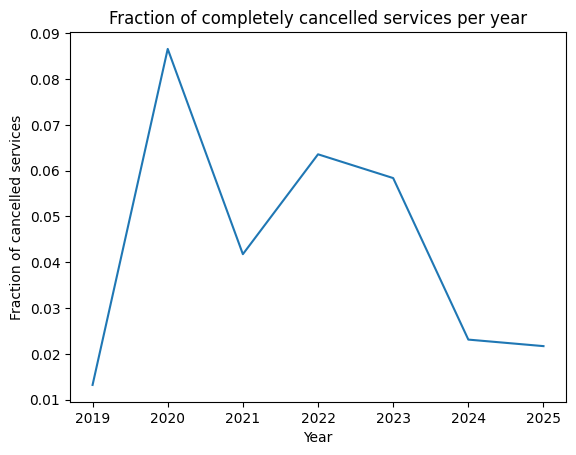

In [16]:
df_cancelled = db.sql("""
SELECT
    YEAR("Service:Date") AS year,
    COUNT(DISTINCT "Service:RDT-ID") FILTER (WHERE "Service:Completely cancelled")
        / COUNT(DISTINCT "Service:RDT-ID") AS fraction_cancelled
FROM services
GROUP BY ALL
ORDER BY year
""").df()

ax = df_cancelled.plot.line(x="year", y="fraction_cancelled", legend=False)
ax.set_title("Fraction of completely cancelled services per year")
ax.set_xlabel("Year")
ax.set_ylabel("Fraction of cancelled services")
plt.show()

### 8. Station connections

8.2 Create table `station_connections`

Following the hint from 8.1, I use `LEAD()` to get the next station of each service, with stops ordered by `Stop:Departure time` (the last stop has NULL there and DuckDB puts NULLs at the end). A-B and B-A is the same pair of stations, so I sort the two codes alphabetically and keep each pair only once. Many services run between the same two stations, so in `Service:RDT-ID` I keep just one of them (the smallest ID). The distance comes from `distances_long`. For pairs that are not in the Dutch tariff matrix it is NULL.

In [17]:
db.sql("""
CREATE OR REPLACE TABLE station_connections AS
WITH consecutive_stations AS (
    SELECT
        "Service:RDT-ID",
        "Stop:Station code" AS station_code,
        LEAD("Stop:Station code") OVER (
            PARTITION BY "Service:RDT-ID"
            ORDER BY "Stop:Departure time"
        ) AS next_station_code
    FROM services
),
station_pairs AS (
    SELECT
        MIN("Service:RDT-ID") AS "Service:RDT-ID",
        LEAST(station_code, next_station_code) AS start_station_code,
        GREATEST(station_code, next_station_code) AS end_station_code
    FROM consecutive_stations
    WHERE next_station_code IS NOT NULL
    GROUP BY ALL
)
SELECT p.*, d.distance
FROM station_pairs AS p
LEFT JOIN distances_long AS d
    ON p.start_station_code = d.station
    AND p.end_station_code = d.other_station
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

8.3 What is the largest distance between a pair of stations?

In [18]:
db.sql("""
SELECT *
FROM station_connections
ORDER BY distance DESC
LIMIT 1
""")

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int64   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│        7122512 │ STV                │ VS               │      421 │
└────────────────┴────────────────────┴──────────────────┴──────────┘

8.4 Plot a histogram of inter-station distances run by trains.

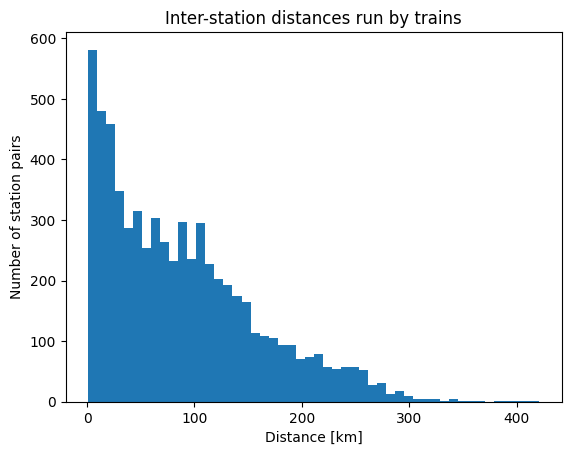

In [19]:
df_connections = db.sql("SELECT distance FROM station_connections").df()

ax = df_connections["distance"].plot.hist(bins=50)
ax.set_title("Inter-station distances run by trains")
ax.set_xlabel("Distance [km]")
ax.set_ylabel("Number of station pairs")
plt.show()